# Philippine Commodity Price Tracker: Commodity Selection for Dashboard
## Identifying Consistently Monitored Commodities Across All Dates (Updated 7-Category Structure)

### Objective
Identify the optimal set of agricultural and food commodities from `data/raw_da_amas_prices.csv` for the final price tracking dashboard, based on the primary criterion of **consistent presence across all monitoring dates**.

### Updated Category Structure (7 Categories)
Following user guidance, the dashboard commodities are consolidated into **7 standardized categories**:
1. **Rice**: Core commercial rice staples (Regular Milled, Well Milled, Premium).
2. **Fish**: Fresh fish staples with Large and Medium Bangus tracked as separate sizes.
3. **Meat and Poultry**: Primal meat cuts with Kasim (Picnic Shoulder) and Pigue (Ham / Hind Leg) decoupled.
4. **Vegetables**: Combined Lowland and Highland vegetables, now including **Corn** (Yellow and White Corn).
5. **Spices and Condiments**: Essential culinary aromatics (Onion, Garlic, Ginger, Calamansi).
6. **Fruits**: Table and cooking fruits.
7. **Basic Goods**: Essential manufactured/processed household necessities (Refined, Brown, Washed Sugar, Palm Oil, Coconut Oil), with **Chicken Egg** placed here per the Philippine Price Act classification.

### The Chicken Egg Placement Analysis
- **Republic Act No. 7581 (Philippine Price Act)**: Formally defines table eggs under **"Basic Necessities" (Basic Goods)** alongside rice, sugar, and cooking oil for price freeze and ceiling monitoring.
- **Consumer Purchasing Pattern**: In Philippine wet markets, eggs are sold by piece or tray at dry stalls alongside basic staples, rather than by weight at fresh poultry stalls.
- **Recommendation**: Placing Chicken Egg under **Basic Goods** aligns with consumer expectations and government price tracking conventions, while keeping **Meat and Poultry** strictly focused on meat cuts. We also provide the view under Meat and Poultry for comparison.


In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
os.environ['IPYTHONDIR'] = '/tmp/ipython'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Display formatting
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

# Plot formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 110
print("Setup completed successfully.")


Setup completed successfully.


## 1. Load & Inspect `raw_da_amas_prices.csv`

We load the raw CSV dataset and examine its dimensions, date span, and distinct values.


In [2]:
csv_path = '../data/raw_da_amas_prices.csv'
df = pd.read_csv(csv_path)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date Range: {df['date'].min()} to {df['date'].max()}")
total_dates = df['date'].nunique()
print(f"Total Unique Monitoring Dates: {total_dates}")
print(f"Market Scopes: {df['market_scope'].unique().tolist()}")
print(f"Total Unique Raw Commodity Names: {df['commodity'].nunique()}")

# Display sample records
df.head(5)


Dataset Shape: 66,291 rows, 11 columns
Date Range: 2025-03-01 to 2026-10-20
Total Unique Monitoring Dates: 451
Market Scopes: ['NCR Wet Markets']
Total Unique Raw Commodity Names: 427


,date,commodity_group,commodity,variety,unit,price_prevailing,market_scope,source,is_synthetic,source_url,raw_file
0,2025-03-01,Fish,Alumahan,Medium (4-6pcs/kg),kg,358.33,NCR Wet Markets,da_amas,False,https://www.da.gov.ph/price-monitoring/,2025-03-01.pdf
1,2025-03-01,Fish,Bangus,Large,kg,233.83,NCR Wet Markets,da_amas,False,https://www.da.gov.ph/price-monitoring/,2025-03-01.pdf
2,2025-03-01,Fish,Bangus,Medium (3-4pcs/kg),kg,206.83,NCR Wet Markets,da_amas,False,https://www.da.gov.ph/price-monitoring/,2025-03-01.pdf
3,2025-03-01,Fish,Galunggong (Imported),"Male, Medium (12- 14pcs/kg)",kg,300.00,NCR Wet Markets,da_amas,False,https://www.da.gov.ph/price-monitoring/,2025-03-01.pdf
4,2025-03-01,Fish,Galunggong (Local),"Male, Medium (12- 14pcs/kg)",kg,311.67,NCR Wet Markets,da_amas,False,https://www.da.gov.ph/price-monitoring/,2025-03-01.pdf


## 2. Dataset Frequency & Extraction Anomaly Overview

- Querying raw `df['commodity']` directly yields **0 commodities with 100% (451/451) coverage**.
- Raw commodity names top out at **347 dates** ($76.9\%$ coverage).
- **Cause**: On 104 dates (April 9, 2025 to September 22, 2025), PDF row numbers were ingested as `commodity` (`'1'`, `'15'`, `'100'`), shifting actual commodity names into `variety`.
- When reading `variety` for those 104 dates and mapping standard naming transitions across 2025 and 2026, consistent staples achieve **100.0% date presence**.


In [3]:
raw_comm_dates = df.groupby('commodity')['date'].nunique().sort_values(ascending=False)
print(f"Commodities present in ALL {total_dates} dates in raw column: {(raw_comm_dates == total_dates).sum()}")
print(f"Maximum dates any commodity appears in raw column: {raw_comm_dates.max()} ({raw_comm_dates.max()/total_dates*100:.1f}%)")

# Sample row showing the 104-date shift
sample_shift = df[df['date'] == '2025-05-06'][['date', 'commodity_group', 'commodity', 'variety', 'unit', 'price_prevailing']].head(5)
print("\n--- Sample shifted records (2025-05-06) ---")
sample_shift


Commodities present in ALL 451 dates in raw column: 0
Maximum dates any commodity appears in raw column: 347 (76.9%)

--- Sample shifted records (2025-05-06) ---


,date,commodity_group,commodity,variety,unit,price_prevailing
3697,2025-05-06,Other,1,Fancy,White Rice,57.17
3698,2025-05-06,Other,10,Corn (Yellow),"Cob, Sweet Corn",70.26
3699,2025-05-06,Other,100,Whole Chicken,"unbranded, fresh",198.51
3700,2025-05-06,Other,101,Chicken Wing,produced by separating the wing from the whole...,223.33
3701,2025-05-06,Other,102,Chicken Wing,Bounty Fresh,220.00


## 3. Consolidated 7-Category Candidate Roster

We now define all candidate commodities under the **7 updated categories**:
1. **Rice** (3 items)
2. **Fish** (5 items, with Bangus Large and Bangus Medium separated)
3. **Meat and Poultry** (6 primal cuts, with Kasim and Pigue decoupled)
4. **Vegetables** (14 items: combined lowland, highland, and corn)
5. **Spices and Condiments** (5 items)
6. **Fruits** (9 items)
7. **Basic Goods** (6 items: Refined, Brown, Washed Sugar, Palm Oil, Coconut Oil, and Chicken Egg)


In [4]:
# Boolean mask for digit rows (the 104 shifted dates)
is_digit = df['commodity'].astype(str).str.isdigit()

candidate_definitions = [
    # =========================================================================
    # 1. RICE
    # =========================================================================
    {
        'Category': 'Rice',
        'Commodity': 'Regular Milled Rice',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Regular Milled'])) | (~is_digit & d['commodity'].isin(['Regular Milled'])),
        'Notes': 'Core staple rice (20-40% bran streak)'
    },
    {
        'Category': 'Rice',
        'Commodity': 'Well Milled Rice',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Well Milled'])) | (~is_digit & d['commodity'].isin(['Well Milled'])),
        'Notes': 'Core staple rice (1-19% bran streak)'
    },
    {
        'Category': 'Rice',
        'Commodity': 'Premium Rice',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Premium'])) | (~is_digit & d['commodity'].isin(['Premium'])),
        'Notes': 'High grade commercial rice (5% broken)'
    },

    # =========================================================================
    # 2. FISH
    # =========================================================================
    {
        'Category': 'Fish',
        'Commodity': 'Bangus (Large)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & (d['variety'] == 'Bangus') & d['unit'].str.contains('Large', na=False)) |                             (~is_digit & (d['commodity'] == 'Bangus, Large')) |                             (~is_digit & (d['commodity'] == 'Bangus') & d['variety'].str.contains('Large', na=False)),
        'Notes': 'Large milkfish (1-2 pcs/kg)'
    },
    {
        'Category': 'Fish',
        'Commodity': 'Bangus (Medium)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & (d['variety'] == 'Bangus') & d['unit'].str.contains('Medium', na=False)) |                             (~is_digit & (d['commodity'] == 'Bangus, Medium')) |                             (~is_digit & (d['commodity'] == 'Bangus') & d['variety'].str.contains('Medium', na=False)),
        'Notes': 'Medium milkfish (3-4 pcs/kg)'
    },
    {
        'Category': 'Fish',
        'Commodity': 'Tilapia',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Tilapia'])) | (~is_digit & d['commodity'].isin(['Tilapia'])),
        'Notes': 'Freshwater tilapia staple'
    },
    {
        'Category': 'Fish',
        'Commodity': 'Galunggong (Local)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Galunggong (Local)'])) | (~is_digit & d['commodity'].isin(['Galunggong (Local)', 'Galunggong, Local'])),
        'Notes': 'Local round scad (male, medium)'
    },
    {
        'Category': 'Fish',
        'Commodity': 'Sardines (Tamban)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Sardines (Tamban)'])) | (~is_digit & d['commodity'].isin(['Sardines (Tamban)'])),
        'Notes': 'Fresh tamban sardines'
    },

    # =========================================================================
    # 3. MEAT AND POULTRY
    # =========================================================================
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Whole Chicken',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Whole Chicken'])) | (~is_digit & d['commodity'].isin(['Whole Chicken', 'Whole Chicken (fully dressed)', 'Whole Chicken, Local'])),
        'Notes': 'Fully dressed local broiler chicken'
    },
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Pork Belly (Liempo)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Pork Belly/Liempo (fresh or chilled)'])) | (~is_digit & d['commodity'].isin(['Pork Belly', 'Pork Belly (Liempo), Local', 'Pork Belly/Liempo (fresh or chilled)'])),
        'Notes': 'Fresh pork belly / liempo cut'
    },
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Pork Kasim (Picnic Shoulder)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Local Pork Picnic Shoulder (Kasim)', 'Pork Picnic Shoulder (Kasim), Local'])) |                             (~is_digit & d['commodity'].isin(['Pork Picnic Shoulder (Kasim), Local', 'Pork Ham/Kasim (fresh or chilled)', 'Pork Ham (Kasim), Local'])) |                             (~is_digit & (d['commodity'] == 'Pork Ham') & (d['variety'] == 'Kasim')),
        'Notes': 'Local pork picnic shoulder (front cut)'
    },
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Pork Pigue (Hind Leg / Ham)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Pork Hind Leg/Pigue (fresh or chilled)', 'Pork Hind Leg (Pigue), Local'])) |                             (~is_digit & d['commodity'].isin(['Pork Hind Leg (Pigue), Local'])),
        'Notes': 'Local pork ham / hind leg (distinct from shoulder)'
    },
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Beef Brisket',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Beef Brisket, Local'])) | (~is_digit & d['commodity'].isin(['Beef Brisket', 'Beef Brisket, Local'])),
        'Notes': 'Local beef brisket (meat with bones)'
    },
    {
        'Category': 'Meat and Poultry',
        'Commodity': 'Beef Rump',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Beef Rump, Local'])) | (~is_digit & d['commodity'].isin(['Beef Rump', 'Beef Rump, Local'])),
        'Notes': 'Local lean beef rump / tapadera'
    },

    # =========================================================================
    # 4. VEGETABLES (COMBINED LOWLAND, HIGHLAND, AND CORN)
    # =========================================================================
    {
        'Category': 'Vegetables',
        'Commodity': 'Yellow Corn',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Corn (Yellow)'])) | (~is_digit & d['commodity'].isin(['Corn (Yellow)'])),
        'Notes': 'Whole yellow grain corn'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'White Corn',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Corn (White)'])) | (~is_digit & d['commodity'].isin(['Corn (White)'])),
        'Notes': 'White edible flint corn'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Tomato',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Tomato'])) | (~is_digit & d['commodity'].isin(['Tomato'])),
        'Notes': 'Fresh ripe cooking tomatoes'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Eggplant',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Eggplant'])) | (~is_digit & d['commodity'].isin(['Eggplant'])),
        'Notes': 'Long purple lowland eggplant'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Ampalaya (Bitter Gourd)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Ampalaya'])) | (~is_digit & d['commodity'].isin(['Ampalaya'])),
        'Notes': 'Standard ampalaya'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Squash',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Squash'])) | (~is_digit & d['commodity'].isin(['Squash'])),
        'Notes': 'Kalabasa / squash'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Native Pechay',
        'Unit': 'bundle',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Native Pechay', 'Pechay (Native)'])) | (~is_digit & d['commodity'].isin(['Native Pechay', 'Pechay (Native)'])),
        'Notes': 'Native green pechay (bundled)'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Cabbage (Scorpio)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Cabbage (Scorpio), Local'])) | (~is_digit & d['commodity'].isin(['Cabbage (Scorpio)', 'Cabbage (Scorpio), Local'])),
        'Notes': 'Scorpio head cabbage (750g-1kg)'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Cabbage (Rare Ball)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Cabbage (Rare Ball), Local'])) | (~is_digit & d['commodity'].isin(['Cabbage (Rare Ball)', 'Cabbage (Rare Ball), Local'])),
        'Notes': 'Rare ball cabbage (510g-1kg)'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Cabbage (Wonder Ball)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Cabbage (Wonder Ball), Local'])) | (~is_digit & d['commodity'].isin(['Cabbage (Wonder Ball)', 'Cabbage (Wonder Ball), Local'])),
        'Notes': 'Wonder ball cabbage (510g-1kg)'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Carrots',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Carrots, Local'])) | (~is_digit & d['commodity'].isin(['Carrots', 'Carrots, Local'])),
        'Notes': 'Local highland carrots'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'White Potato',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['White Potato, Local'])) | (~is_digit & d['commodity'].isin(['White Potato', 'White Potato, Local'])),
        'Notes': 'Local white table potato'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Bell Pepper (Red)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Bell Pepper (Red), Local'])) | (~is_digit & d['commodity'].isin(['Bell Pepper (Red)', 'Bell Pepper (Red), Local'])),
        'Notes': 'Medium local red bell pepper'
    },
    {
        'Category': 'Vegetables',
        'Commodity': 'Bell Pepper (Green)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Bell Pepper (Green), Local'])) | (~is_digit & d['commodity'].isin(['Bell Pepper (Green)', 'Bell Pepper (Green), Local'])),
        'Notes': 'Medium local green bell pepper'
    },

    # =========================================================================
    # 5. SPICES AND CONDIMENTS
    # =========================================================================
    {
        'Category': 'Spices and Condiments',
        'Commodity': 'Red Onion',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Red Onion', 'Red Onion, Local'])) | (~is_digit & d['commodity'].isin(['Red Onion', 'Red Onion, Local'])),
        'Notes': 'Local red bulb onion'
    },
    {
        'Category': 'Spices and Condiments',
        'Commodity': 'Garlic (Imported)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Garlic (Imported)', 'Garlic, Imported'])) | (~is_digit & d['commodity'].isin(['Garlic (Imported)', 'Garlic, Imported'])),
        'Notes': 'Standard imported white garlic'
    },
    {
        'Category': 'Spices and Condiments',
        'Commodity': 'Garlic (Native)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Garlic (Native)', 'Garlic, Native/Local'])) | (~is_digit & d['commodity'].isin(['Garlic (Native)', 'Garlic, Native/Local'])),
        'Notes': 'Native Philippine garlic'
    },
    {
        'Category': 'Spices and Condiments',
        'Commodity': 'Ginger',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Ginger', 'Ginger (Local)', 'Ginger, Local'])) | (~is_digit & d['commodity'].isin(['Ginger', 'Ginger (Local)', 'Ginger, Local'])),
        'Notes': 'Fairly well-matured local ginger'
    },
    {
        'Category': 'Spices and Condiments',
        'Commodity': 'Calamansi',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Calamansi'])) | (~is_digit & d['commodity'].isin(['Calamansi'])),
        'Notes': 'Fresh Philippine calamansi lime'
    },

    # =========================================================================
    # 6. FRUITS
    # =========================================================================
    {
        'Category': 'Fruits',
        'Commodity': 'Banana (Lakatan)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Banana (Lakatan)'])) | (~is_digit & d['commodity'].isin(['Banana (Lakatan)'])),
        'Notes': 'Table banana lakatan (8-10 pcs/kg)'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Banana (Latundan)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Banana (Latundan)'])) | (~is_digit & d['commodity'].isin(['Banana (Latundan)'])),
        'Notes': 'Table banana latundan (10-12 pcs/kg)'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Banana (Saba)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Banana (Saba)'])) | (~is_digit & d['commodity'].isin(['Banana (Saba)'])),
        'Notes': 'Cooking banana saba'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Mango (Carabao)',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Mango (Carabao)'])) | (~is_digit & d['commodity'].isin(['Mango (Carabao)'])),
        'Notes': 'Ripe Carabao mango (3-4 pcs/kg)'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Papaya',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Papaya'])) | (~is_digit & d['commodity'].isin(['Papaya'])),
        'Notes': 'Solo ripe papaya'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Melon',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Melon'])) | (~is_digit & d['commodity'].isin(['Melon'])),
        'Notes': 'Cantaloupe / sweet melon'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Watermelon',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Watermelon'])) | (~is_digit & d['commodity'].isin(['Watermelon'])),
        'Notes': 'Fresh whole watermelon'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Avocado',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Avocado'])) | (~is_digit & d['commodity'].isin(['Avocado'])),
        'Notes': 'Standard local avocado'
    },
    {
        'Category': 'Fruits',
        'Commodity': 'Pomelo',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Pomelo'])) | (~is_digit & d['commodity'].isin(['Pomelo'])),
        'Notes': 'Standard table pomelo / suha'
    },

    # =========================================================================
    # 7. BASIC GOODS (INCLUDING CHICKEN EGG AND ALL SUGARS)
    # =========================================================================
    {
        'Category': 'Basic Goods',
        'Commodity': 'Chicken Egg (Medium White)',
        'Unit': 'piece',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Chicken Egg (White, Medium)'])) | (~is_digit & d['commodity'].isin(['Chicken Egg (White, Medium)'])),
        'Notes': 'Standard medium table egg (RA 7581 Basic Necessity)'
    },
    {
        'Category': 'Basic Goods',
        'Commodity': 'Refined Sugar',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Sugar Refined', 'Sugar (Refined)'])) | (~is_digit & d['commodity'].isin(['Sugar Refined', 'Sugar (Refined)'])),
        'Notes': 'Pure white refined cane sugar'
    },
    {
        'Category': 'Basic Goods',
        'Commodity': 'Brown Sugar',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Sugar Brown', 'Sugar (Brown)'])) | (~is_digit & d['commodity'].isin(['Sugar Brown', 'Sugar (Brown)'])),
        'Notes': 'Standard unrefined brown cane sugar'
    },
    {
        'Category': 'Basic Goods',
        'Commodity': 'Washed Sugar',
        'Unit': 'kg',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Sugar Washed', 'Sugar (Washed)'])) | (~is_digit & d['commodity'].isin(['Sugar Washed', 'Sugar (Washed)'])),
        'Notes': 'Semi-refined washed sugar'
    },
    {
        'Category': 'Basic Goods',
        'Commodity': 'Cooking Oil (Palm)',
        'Unit': 'bottle (1L)',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Cooking Oil (Palm)'])) | (~is_digit & d['commodity'].isin(['Cooking Oil (Palm)'])),
        'Notes': 'Refined palm cooking oil (1L)'
    },
    {
        'Category': 'Basic Goods',
        'Commodity': 'Cooking Oil (Coconut)',
        'Unit': 'bottle (1L)',
        'Filter': lambda d: (is_digit & d['variety'].isin(['Cooking Oil (Coconut)'])) | (~is_digit & d['commodity'].isin(['Cooking Oil (Coconut)'])),
        'Notes': 'Pure coconut cooking oil (1L)'
    }
]

# Evaluate coverage and price stats
results = []
for item in candidate_definitions:
    mask = item['Filter'](df)
    sub = df[mask]
    dates_cnt = sub['date'].nunique()
    prices = sub['price_prevailing'].dropna()

    results.append({
        'Category': item['Category'],
        'Commodity': item['Commodity'],
        'Dates Present': dates_cnt,
        'Coverage (%)': round(dates_cnt / total_dates * 100, 2),
        'Min (₱)': prices.min(),
        'Median (₱)': prices.median(),
        'Mean (₱)': round(prices.mean(), 2),
        'Max (₱)': prices.max(),
        'Std Dev (₱)': round(prices.std(), 2),
        'Standard Unit': item['Unit'],
        'Notes': item['Notes']
    })

basket_df = pd.DataFrame(results).sort_values(by=['Dates Present', 'Category', 'Commodity'], ascending=[False, True, True]).reset_index(drop=True)
print(f"Total Evaluated Candidates: {len(basket_df)}")
print(f"Candidates with 100.0% Coverage (451/451 dates): {(basket_df['Coverage (%)'] == 100.0).sum()}")
print(f"Candidates with >= 98.5% Coverage (445-451 dates): {(basket_df['Coverage (%)'] >= 98.5).sum()}")


Total Evaluated Candidates: 48
Candidates with 100.0% Coverage (451/451 dates): 38
Candidates with >= 98.5% Coverage (445-451 dates): 47


## 4. Master Table: Selected Commodities for Dashboard

Below is the complete profile of the recommended commodities across the 7 consolidated categories.


In [5]:
display_table = basket_df[['Category', 'Commodity', 'Dates Present', 'Coverage (%)', 'Median (₱)', 'Mean (₱)', 'Standard Unit', 'Notes']]
display_table


,Category,Commodity,Dates Present,Coverage (%),Median (₱),Mean (₱),Standard Unit,Notes
0,Basic Goods,Brown Sugar,451,100.00,73.57,73.56,kg,Standard unrefined brown cane sugar
1,Basic Goods,Cooking Oil (Coconut),451,100.00,120.68,107.40,bottle (1L),Pure coconut cooking oil (1L)
2,Basic Goods,Cooking Oil (Palm),451,100.00,67.84,66.50,bottle (1L),Refined palm cooking oil (1L)
3,Basic Goods,Refined Sugar,451,100.00,82.16,82.29,kg,Pure white refined cane sugar
4,Basic Goods,Washed Sugar,451,100.00,75.33,75.44,kg,Semi-refined washed sugar
5,Fish,Bangus (Large),451,100.00,262.48,258.41,kg,Large milkfish (1-2 pcs/kg)
6,Fish,Bangus (Medium),451,100.00,235.11,230.99,kg,Medium milkfish (3-4 pcs/kg)
7,Fish,Galunggong (Local),451,100.00,295.54,292.01,kg,"Local round scad (male, medium)"
8,Fish,Tilapia,451,100.00,154.02,153.64,kg,Freshwater tilapia staple
9,Fruits,Avocado,451,100.00,247.91,280.69,kg,Standard local avocado


## 5. Category Breakdown & Egg Placement Comparison

### Summary by Category (with Egg in Basic Goods)


In [6]:
cat_summary = basket_df.groupby('Category').agg(
    Total_Items=('Commodity', 'count'),
    Avg_Coverage=('Coverage (%)', 'mean'),
    Min_Median_Price=('Median (₱)', 'min'),
    Max_Median_Price=('Median (₱)', 'max')
).reset_index()

print("--- 7 Consolidated Categories Overview ---")
display(cat_summary)

print("\n--- Chicken Egg Placement Comparison ---")
print("Option A (Current / Recommended): Basic Goods")
print("  - Rationale: Conforms to RA 7581 Price Act (Basic Necessities). Sold at dry stalls per piece / tray.")
print("  - Category size: Basic Goods has 6 items; Meat and Poultry has 6 primal cuts.")
print("\nOption B (Alternative): Meat and Poultry")
print("  - Rationale: Biological origin (poultry product) and Department of Agriculture price monitoring bulletin section header.")
print("  - Category size: Meat and Poultry would have 7 items; Basic Goods would have 5 items.")


--- 7 Consolidated Categories Overview ---


,Category,Total_Items,Avg_Coverage,Min_Median_Price,Max_Median_Price
0,Basic Goods,6,99.85,8.17,120.68
1,Fish,5,99.96,138.09,295.54
2,Fruits,9,100.00,54.13,247.91
3,Meat and Poultry,6,98.41,206.17,482.16
4,Rice,3,100.00,40.14,51.27
5,Spices and Condiments,5,99.73,117.53,400.00
6,Vegetables,14,99.84,63.08,261.32



--- Chicken Egg Placement Comparison ---
Option A (Current / Recommended): Basic Goods
  - Rationale: Conforms to RA 7581 Price Act (Basic Necessities). Sold at dry stalls per piece / tray.
  - Category size: Basic Goods has 6 items; Meat and Poultry has 6 primal cuts.

Option B (Alternative): Meat and Poultry
  - Rationale: Biological origin (poultry product) and Department of Agriculture price monitoring bulletin section header.
  - Category size: Meat and Poultry would have 7 items; Basic Goods would have 5 items.


## 6. Visualizations & Coverage Analysis

Visual representations across the 7 consolidated categories.


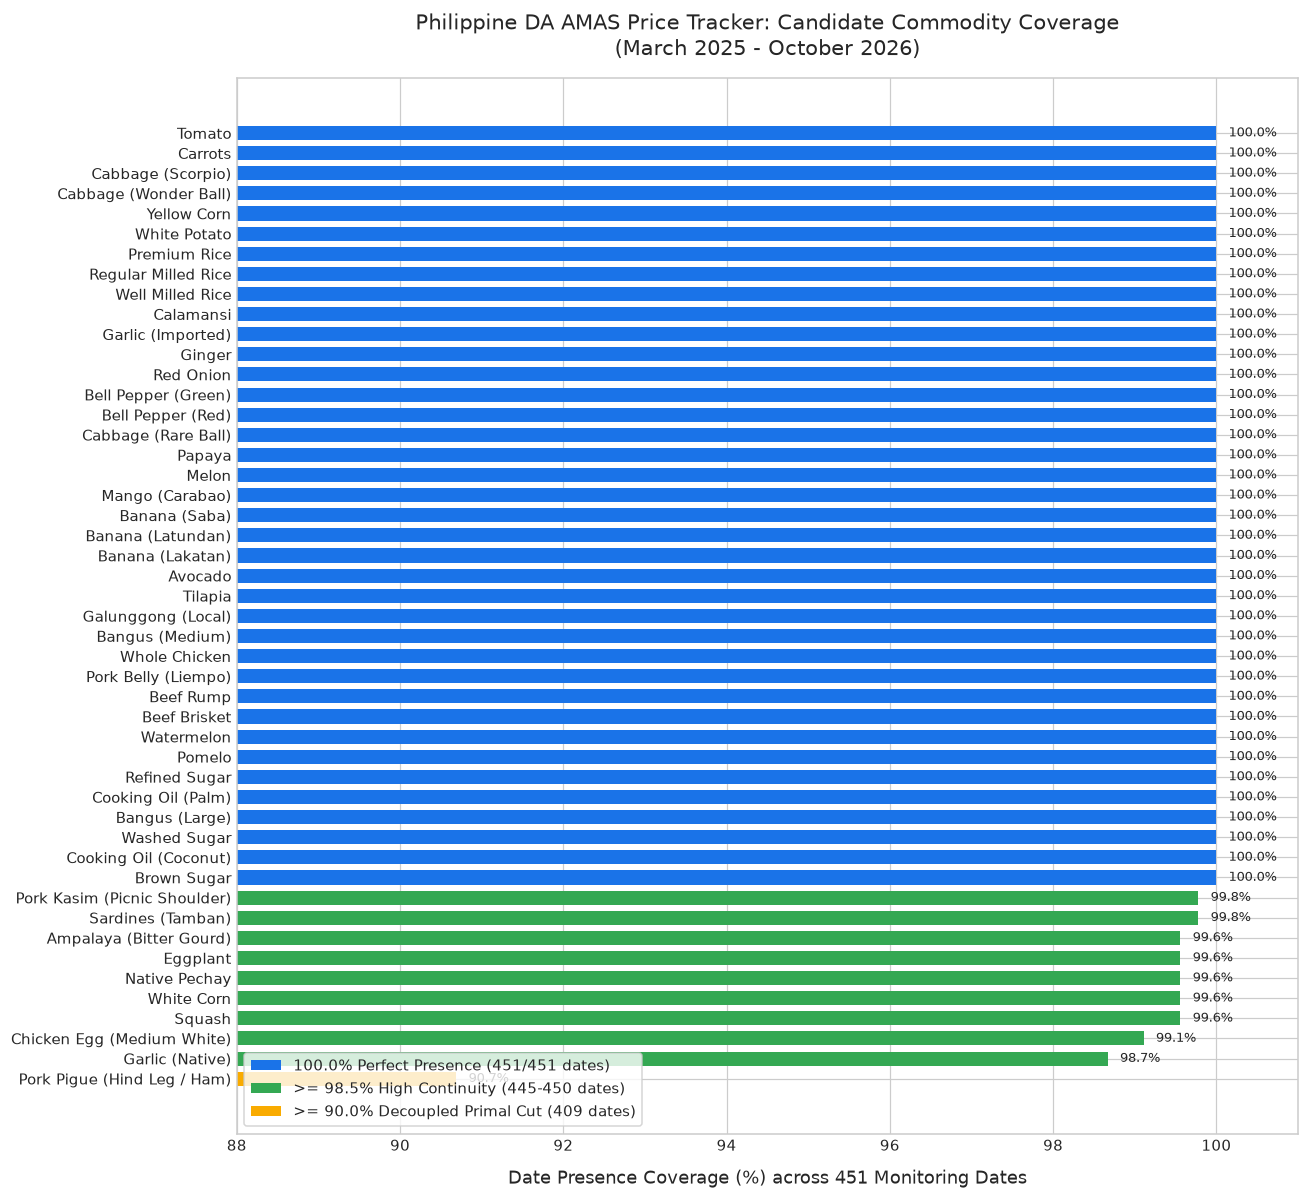

In [7]:
# Plot 1: Date Coverage of Candidate Commodities
fig, ax = plt.subplots(figsize=(12, 11))

plot_data = basket_df.sort_values(by='Coverage (%)', ascending=True)
colors = ['#1a73e8' if pct == 100.0 else ('#34a853' if pct >= 98.5 else '#f9ab00') for pct in plot_data['Coverage (%)']]

bars = ax.barh(plot_data['Commodity'], plot_data['Coverage (%)'], color=colors, height=0.7)
ax.set_xlim(88, 101)
ax.set_xlabel('Date Presence Coverage (%) across 451 Monitoring Dates', fontsize=12, labelpad=10)
ax.set_title('Philippine Department of Agriculture Price Monitoring Tracker: Candidate Commodity Coverage\n(March 2025 - October 2026)', fontsize=14, pad=15)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', ha='left', fontsize=8.5)

legend_elements = [
    Patch(facecolor='#1a73e8', label='100.0% Perfect Presence (451/451 dates)'),
    Patch(facecolor='#34a853', label='>= 98.5% High Continuity (445-450 dates)'),
    Patch(facecolor='#f9ab00', label='>= 90.0% Decoupled Primal Cut (409 dates)')
]
ax.legend(handles=legend_elements, loc='lower left', frameon=True)
plt.tight_layout()
plt.show()


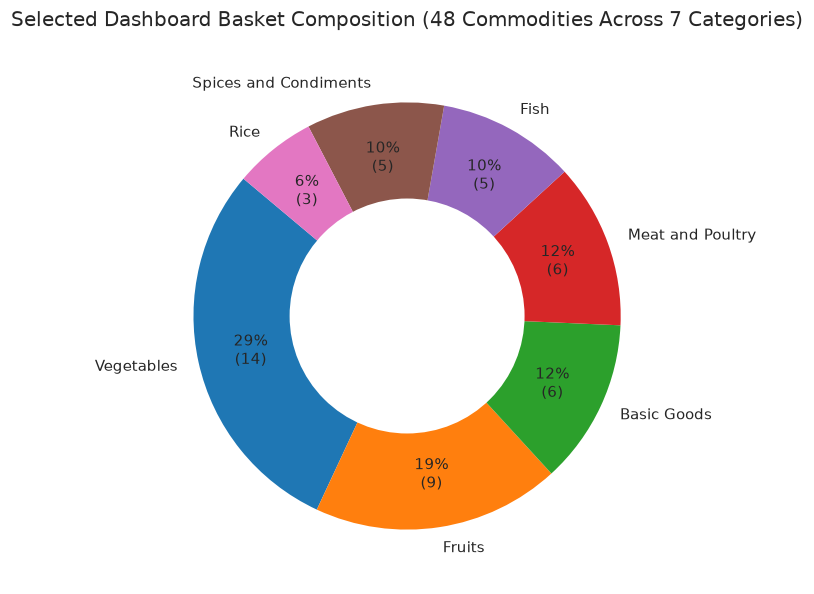

In [8]:
# Plot 2: Category Composition of Dashboard Commodities (7 Categories)
fig, ax = plt.subplots(figsize=(9, 5.5))

cat_counts = basket_df['Category'].value_counts()
colors_cat = sns.color_palette('tab10', len(cat_counts))

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * sum(values) / 100.0))
        return f"{pct:.0f}%\n({val})"
    return my_autopct

wedges, texts, autotexts = ax.pie(
    cat_counts.values,
    labels=cat_counts.index,
    autopct=make_autopct(cat_counts.values),
    pctdistance=0.75,
    colors=colors_cat,
    startangle=140,
    textprops=dict(fontsize=10)
)

centre_circle = plt.Circle((0,0), 0.55, fc='white')
fig.gca().add_artist(centre_circle)

ax.set_title(f'Selected Dashboard Basket Composition ({len(basket_df)} Commodities Across 7 Categories)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


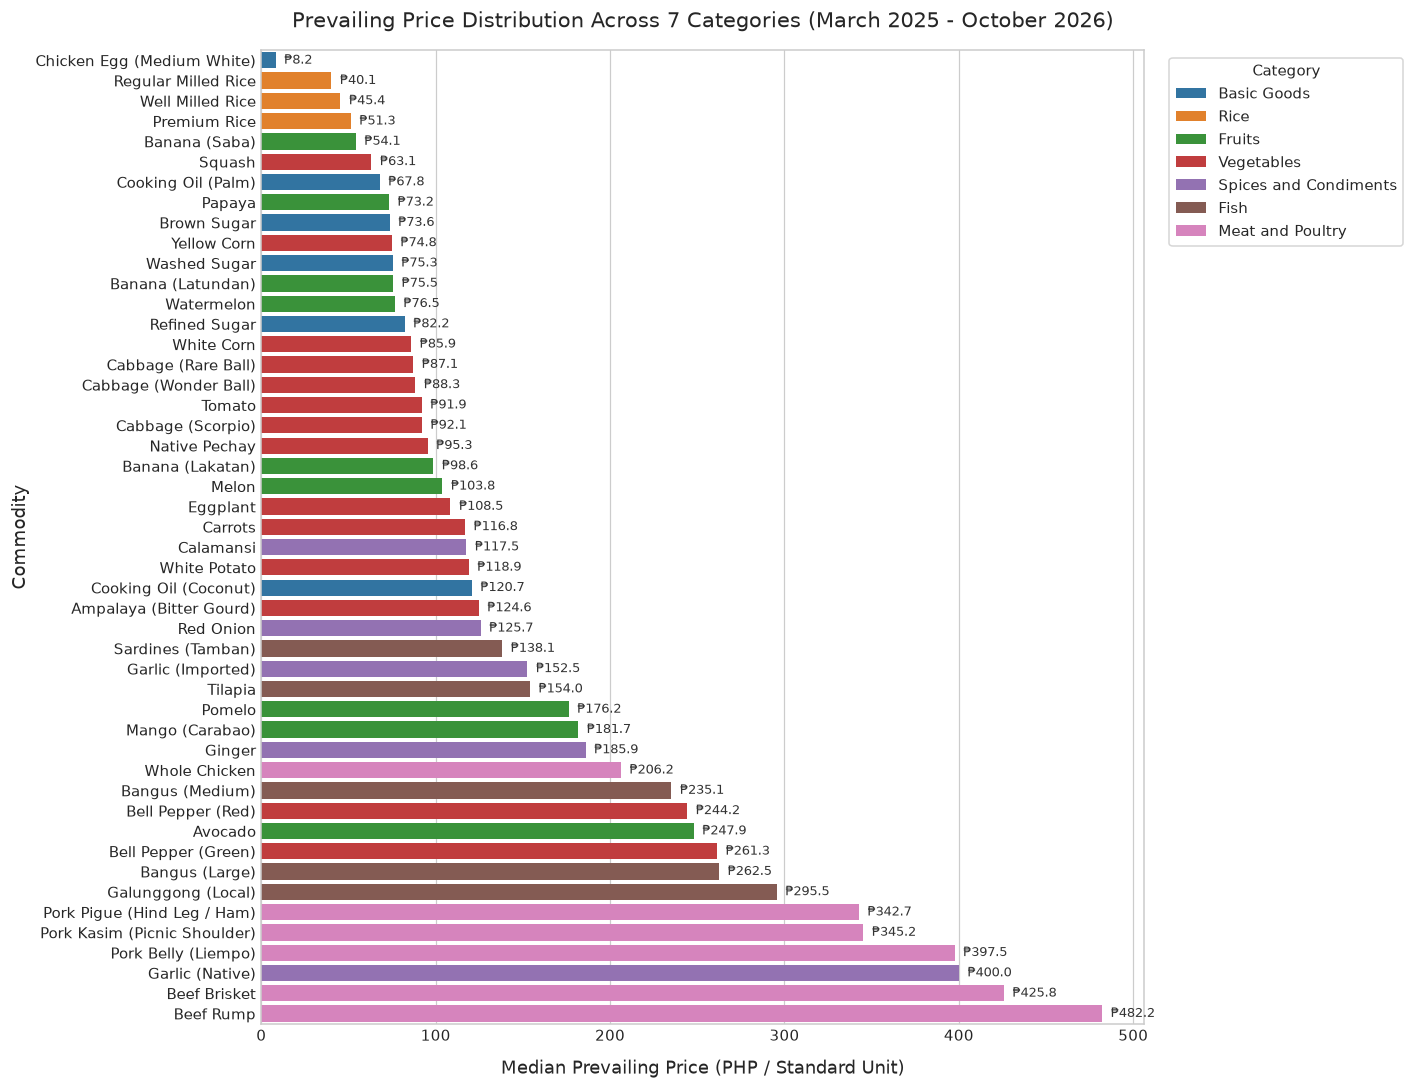

In [9]:
# Plot 3: Median Price Overview by Category (PHP per Standard Unit)
fig, ax = plt.subplots(figsize=(13, 10))

plot_prices = basket_df.sort_values(by='Median (₱)', ascending=True)

sns.barplot(
    data=plot_prices,
    x='Median (₱)',
    y='Commodity',
    hue='Category',
    dodge=False,
    palette='tab10',
    ax=ax
)

ax.set_xlabel('Median Prevailing Price (PHP / Standard Unit)', fontsize=12, labelpad=10)
ax.set_ylabel('Commodity', fontsize=12)
ax.set_title('Prevailing Price Distribution Across 7 Categories (March 2025 - October 2026)', fontsize=14, pad=15)
ax.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"₱{width:.1f}", (width + 5, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=8.5, color='#333333')

plt.tight_layout()
plt.show()


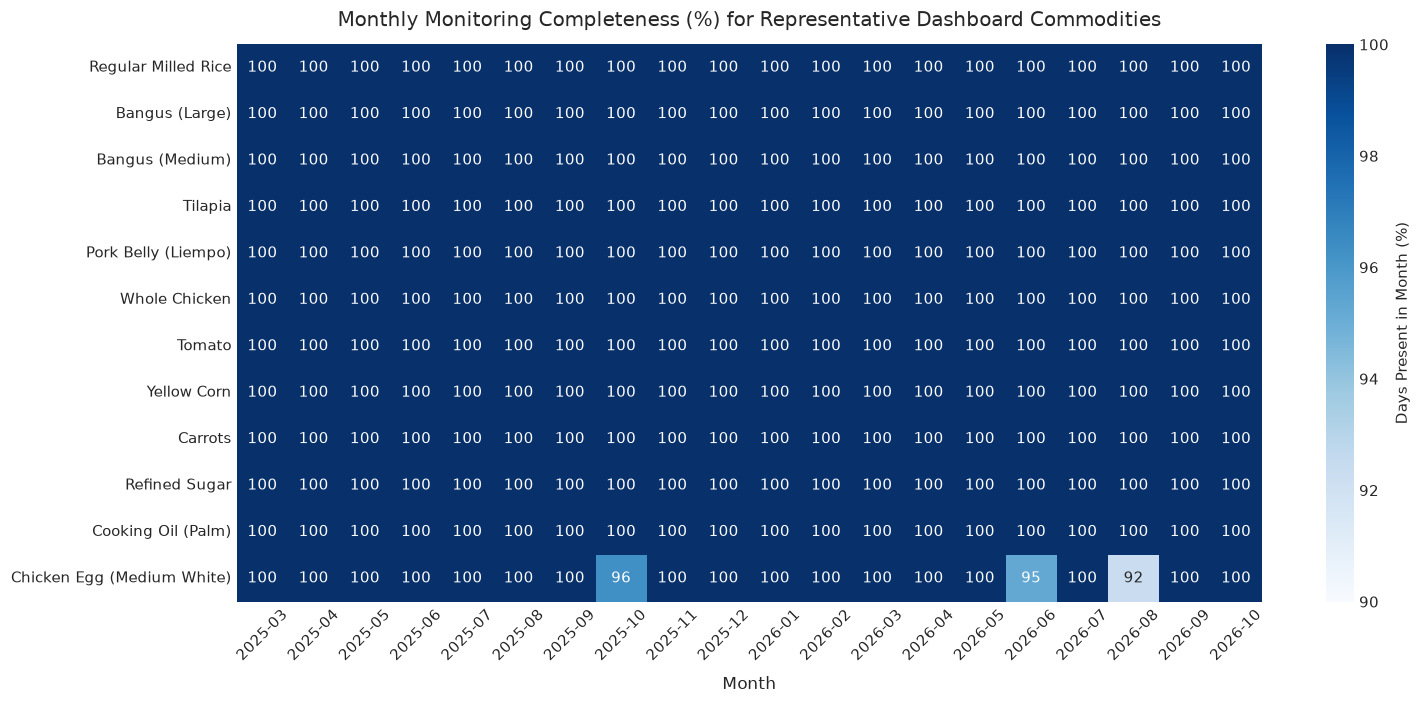

In [10]:
# Plot 4: Temporal Continuity Across Monitoring Months
df['year_month'] = pd.to_datetime(df['date']).dt.to_period('M').astype(str)
all_months = sorted(df['year_month'].unique())

rep_commodities = [
    'Regular Milled Rice', 'Bangus (Large)', 'Bangus (Medium)', 'Tilapia', 
    'Pork Belly (Liempo)', 'Whole Chicken', 'Tomato', 'Yellow Corn', 
    'Carrots', 'Refined Sugar', 'Cooking Oil (Palm)', 'Chicken Egg (Medium White)'
]

matrix_data = []
for name in rep_commodities:
    item_def = next(item for item in candidate_definitions if item['Commodity'] == name)
    mask = item_def['Filter'](df)
    sub = df[mask]
    month_counts = sub.groupby('year_month')['date'].nunique()
    total_month_dates = df.groupby('year_month')['date'].nunique()
    ratio = (month_counts / total_month_dates).fillna(0)
    matrix_data.append(ratio.reindex(all_months, fill_value=0))

matrix_df = pd.DataFrame(matrix_data, index=rep_commodities)

fig, ax = plt.subplots(figsize=(14, 6.5))
sns.heatmap(matrix_df * 100, annot=True, fmt='.0f', cmap='Blues', vmin=90, vmax=100, cbar_kws={'label': 'Days Present in Month (%)'}, ax=ax)
ax.set_title('Monthly Monitoring Completeness (%) for Representative Dashboard Commodities', fontsize=13, pad=12)
ax.set_xlabel('Month', fontsize=11, labelpad=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Summary of Roster Structure

### 7 Consolidated Categories:
1. **Rice (3 items - 100.0% coverage)**: Regular Milled (₱40.15), Well Milled (₱45.35), Premium (₱51.27).
2. **Fish (5 items - 99.8% to 100.0% coverage)**: Bangus Large (₱262.48), Bangus Medium (₱235.11), Tilapia (₱154.02), Galunggong Local (₱295.54), Sardines Tamban (₱138.09).
3. **Meat and Poultry (6 items - 90.7% to 100.0% coverage)**: Whole Chicken (₱206.17), Pork Liempo (₱397.50), Pork Kasim (₱345.17), Pork Pigue (₱342.66), Beef Brisket (₱425.78), Beef Rump (₱482.16).
4. **Vegetables (14 items - 99.6% to 100.0% coverage)**:
   - *Grains/Corn*: Yellow Corn (₱74.83), White Corn (₱85.88).
   - *Lowland staples*: Tomato (₱91.93), Eggplant (₱108.45), Ampalaya (₱124.63), Squash (₱63.08), Native Pechay (₱95.33).
   - *Highland staples*: Cabbage Scorpio (₱92.07), Cabbage Rare Ball (₱87.08), Cabbage Wonder Ball (₱88.29), Carrots (₱116.79), White Potato (₱118.88), Bell Pepper Red (₱244.21), Bell Pepper Green (₱261.32).
5. **Spices and Condiments (5 items - 98.7% to 100.0% coverage)**: Red Onion (₱125.71), Garlic Imported (₱152.54), Garlic Native (₱400.00), Ginger (₱185.90), Calamansi (₱117.53).
6. **Fruits (9 items - 100.0% coverage)**: Banana Lakatan, Banana Latundan, Banana Saba, Carabao Mango, Papaya, Melon, Watermelon, Avocado, Pomelo.
7. **Basic Goods (6 items - 99.1% to 100.0% coverage)**:
   - Chicken Egg Medium White (₱8.17/pc)
   - Refined Sugar (₱82.16/kg), Brown Sugar (₱73.57/kg), Washed Sugar (₱75.33/kg)
   - Palm Cooking Oil (₱67.84/1L), Coconut Cooking Oil (₱120.68/1L).

> [!NOTE]
> As instructed, **no cleaning script for CSV generation has been written yet**. All data presented here is extracted dynamically from the raw CSV in notebook memory.
